# Day 2: answering the question

**Python for Data Analysis**, Coding for Reproducible Research (CfRR), University of Exeter

Yesterday we cleaned every month of Oxford weather since 1853 and found that summer 2026 tops the ranking. Today we find out whether that means anything: we plot it, fit a trend, bring in a second station, try some machine learning, and make sure the whole analysis can be rerun by someone else.

## By the end of today you will be able to

- explain why a notebook must run top to bottom from a fresh kernel
- build a matplotlib figure step by step with `fig, ax`, and save it
- make the same chart interactive with Plotly, and say when each is the better tool
- fit a straight-line trend and say what it can and cannot tell you
- turn repeated steps into a function and check it with `assert`
- use scikit-learn's `fit`/`predict`/`score` pattern, and test a model honestly

## How to use this notebook

As yesterday: type along in a fresh notebook of your own, and copy any cell you miss from here. Exercises are labelled **Predict**, **Investigate**, **Modify**, **Spot the bug**, **Describe first**, **Decide together** or **Make**.

*Data: Met Office historic station data for Oxford and Lerwick. Contains public sector information licensed under the [Open Government Licence v3.0](https://www.nationalarchives.gov.uk/doc/open-government-licence/version/3/).*

## 1. Recap, and "Restart and run all"

*10:00, 15 minutes*

Yesterday's cleaning lives in `day2_checkpoint.ipynb`. The cell below downloads that notebook, then the `%run` line runs it and hands us its variables, including the cleaned `oxford` DataFrame.

In [1]:
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px

BASE = "https://raw.githubusercontent.com/cafoala/cfrr-python-for-data-analysis/snapshot-2026-10-29/"
urlretrieve(BASE + "notebooks/day2_checkpoint.ipynb", "day2_checkpoint.ipynb")

%run day2_checkpoint.ipynb
oxford.shape

(2085, 14)

The checkpoint also defined the file location and column names we will reuse later.

In [2]:
OXFORD, COLUMNS, MEASURES

(PosixPath('data/oxforddata.txt'),
 ['yyyy', 'mm', 'tmax', 'tmin', 'af', 'rain', 'sun', 'status'],
 ['tmax', 'tmin', 'af', 'rain', 'sun'])

**Spot the bug.** Watch the instructor's screen. The `summer_tmax` cell works, the cell that defined `summer` gets deleted, and the notebook still seems fine. Then **Kernel > Restart Kernel and Run All Cells**. What breaks, and why did it work before?

In [3]:
summer = oxford[oxford["mm"].isin([6, 7, 8])]

In [4]:
summer_tmax = summer.groupby("yyyy")["tmax"].mean()
summer_tmax.tail(3)

yyyy
2024    21.966667
2025    24.500000
2026    26.166667
Name: tmax, dtype: float64

**Answer.** `summer` was defined in a cell that was later deleted. The variable stayed in the kernel's memory, so everything kept working until the kernel restarted. A notebook remembers everything you have ever run, in the order you ran it, not the order on the page. The only reliable test is to restart and run everything from the top. Fix it by putting the missing line back, above the cell that uses it.

## 2. Seeing it

*10:15, 45 minutes*

A matplotlib chart has two main objects: the **Figure** (the whole image) and the **Axes** (one plot inside it, with its own axes, labels and lines). Every chart here starts with `fig, ax = plt.subplots()` and then adds things to `ax`. Writing it this way takes a few more lines than a one-liner, but you control everything. The [CfRR Matplotlib page](https://coding-for-reproducible-research.github.io/CfRR_Courses/individual_modules/python_for_data_analysis/Python_Matplotlib.html) has many more chart types.

Start with every month in the record.

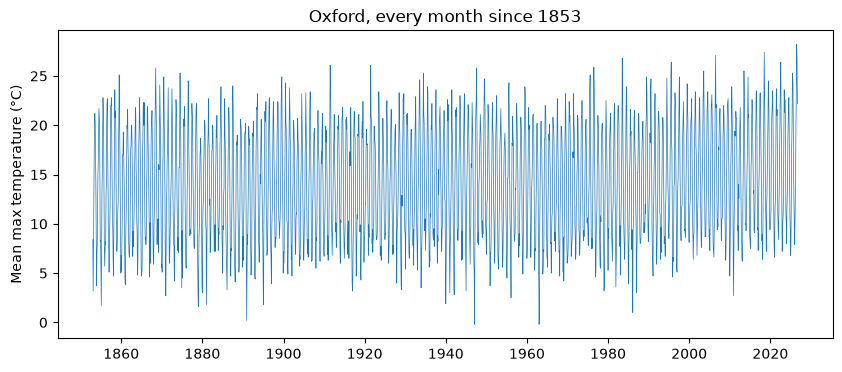

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(oxford.index, oxford["tmax"], linewidth=0.5)
ax.set_ylabel("Mean max temperature (°C)")
ax.set_title("Oxford, every month since 1853")
plt.show()

Unreadable: the seasonal cycle swamps everything else. Choose the chart for the question. Ours is about summers, so plot one value per summer.

(Why not the mean for each calendar year? 2026 only has nine months so far, all from the warmer part of the year, which would flatter it.)

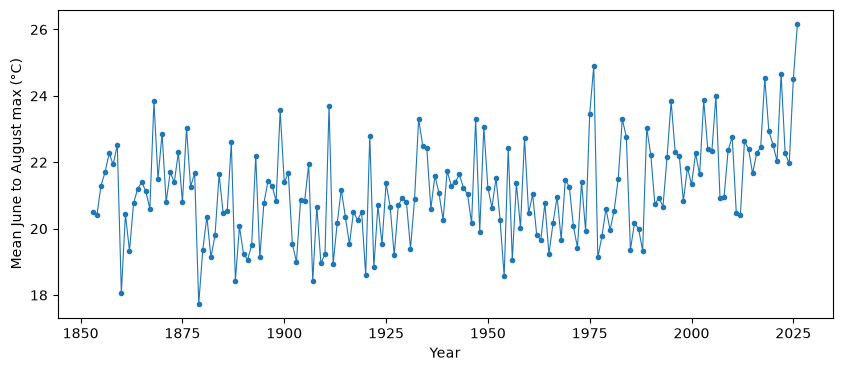

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(summer_tmax.index, summer_tmax, marker=".", linewidth=0.8)
ax.set_xlabel("Year")
ax.set_ylabel("Mean June to August max (°C)")
plt.show()

Year-to-year noise hides any slow change. A 10-year rolling mean averages each summer with the nine before it.

**Modify.** Add the rolling mean to the chart as a second, thicker line, and add a legend.

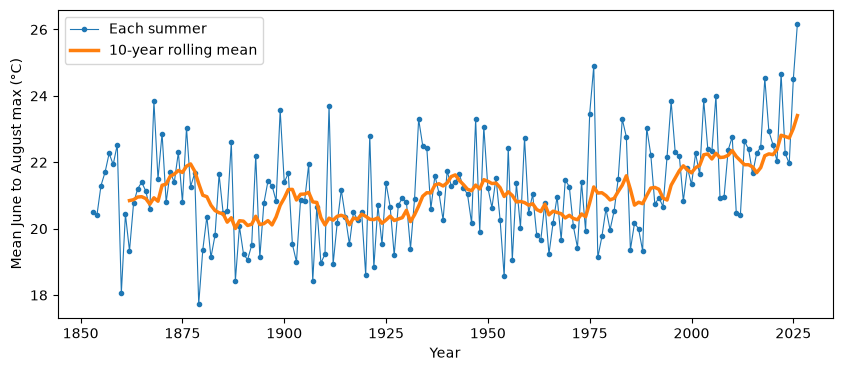

In [7]:
rolling = summer_tmax.rolling(10).mean()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(summer_tmax.index, summer_tmax, marker=".", linewidth=0.8, label="Each summer")
ax.plot(rolling.index, rolling, linewidth=2.5, label="10-year rolling mean")
ax.set_xlabel("Year")
ax.set_ylabel("Mean June to August max (°C)")
ax.legend()
plt.show()

**Modify.** Because we kept hold of `ax`, we can keep adding to the same chart. Highlight 2026, then save the figure as a file you could put in a paper.

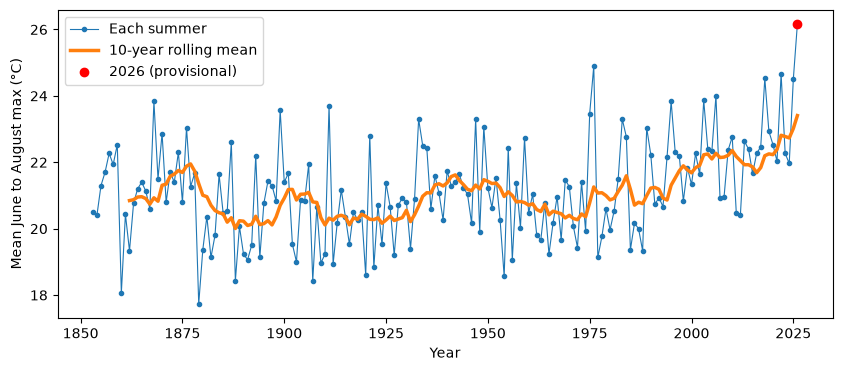

In [8]:
ax.scatter(2026, summer_tmax[2026], color="red", zorder=3, label="2026 (provisional)")
ax.legend()
fig.savefig("summer_tmax.png", dpi=200, bbox_inches="tight")
fig

**Make.** Plot your own choice of month across the whole record. Is the pattern the same as for summer?

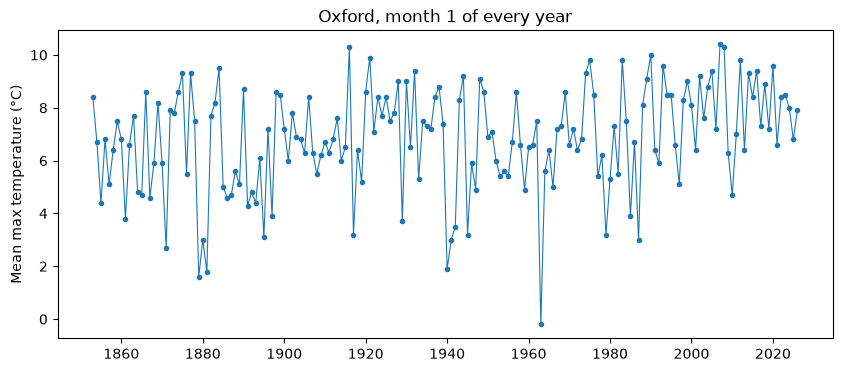

In [9]:
month = 1  # January
chosen = oxford[oxford["mm"] == month]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(chosen.index, chosen["tmax"], marker=".", linewidth=0.8)
ax.set_ylabel("Mean max temperature (°C)")
ax.set_title(f"Oxford, month {month} of every year")
plt.show()

### The same thing with Plotly

*Last 15 minutes of this block*

Plotly makes interactive charts that you can hover over, zoom and pan. `plotly.express` builds a whole chart in one call. The [CfRR Plotly page](https://coding-for-reproducible-research.github.io/CfRR_Courses/individual_modules/python_for_data_analysis/data-analysis-plotly.html) goes further.

In [10]:
px.line(summer_tmax.reset_index(), x="yyyy", y="tmax", markers=True,
        labels={"yyyy": "Year", "tmax": "Mean June to August max (°C)"})

**Investigate.** Hover to find the three hottest summers. Drag across the 1970s to zoom in, and double-click to zoom back out.

Which tool, when?

- **Plotly:** quick to write and good for exploring; charts can be shared as web pages.
- **matplotlib:** more lines of code, but control over every detail, and it saves the static image files that journals want. (Plotly can save static images too, but needs the extra `kaleido` package and a copy of Chrome.)

**Make (optional).** Recreate the rolling-mean chart in Plotly. What is easier, and what is harder?

## 3. Is it a trend?

*11:00, 25 minutes*

`np.polyfit(x, y, 1)` finds the straight line that best fits the points (degree 1 means a straight line). It returns the slope and the intercept.

**Predict.** Will the slope be positive or negative? Roughly how many degrees per decade?

In [11]:
slope, intercept = np.polyfit(summer_tmax.index, summer_tmax, 1)
slope * 10  # °C per decade

np.float64(0.09350076406883245)

**Modify.** Fit the line again using only summers from 1970 onwards. How does the slope change?

In [12]:
recent = summer_tmax.loc[1970:]
recent_slope, recent_intercept = np.polyfit(recent.index, recent, 1)
recent_slope * 10  # °C per decade

np.float64(0.47024889810733184)

**Answer.** About five times steeper. A single line through every summer since 1853 hides the fact that most of the warming is recent. The start year is a choice, and it changes the answer.

### Unusual for its time?

Summers are warming, so a record is less surprising than it used to be. A fairer question: how far is 2026 from what the recent trend would predict? We fit the line to 1970 to 2025, so 2026 cannot pull the line towards itself, then compare the gap with the typical scatter of summers around the line.

In [13]:
before = summer_tmax.loc[1970:2025]
trend_slope, trend_intercept = np.polyfit(before.index, before, 1)
expected_2026 = trend_slope * 2026 + trend_intercept
scatter = (before - (trend_slope * before.index + trend_intercept)).std()
summer_tmax[2026] - expected_2026, scatter

(np.float64(3.2015800865800905), np.float64(1.2996161851532457))

What a line can and cannot tell you:

- It **can** summarise the average rate of change over the years you chose.
- It **cannot** tell you why, or promise that the next ten years will follow it.
- 2026 is still **provisional**, and every 2026 temperature is estimated. The Met Office may revise them.

## Break

*11:25, 15 minutes*

## 4. A second station

*11:40, 30 minutes*

Is Oxford typical? Lerwick, in Shetland, is over 900 km further north (60.14°N, 1.18°W, 82 metres above sea level) and surrounded by sea. Its record starts in December 1930. Yesterday's cleaning steps need to run again for a second file, so we turn them into a function.

**Modify.** Turn the steps in `day2_checkpoint.ipynb` into a function `load_station(path)` that returns the cleaned DataFrame.

In [14]:
def load_station(path):
    df = pd.read_csv(path, sep=r"\s+", skiprows=7, names=COLUMNS, na_values="---")
    for col in MEASURES:
        text = df[col].astype(str)
        df[col + "_estimated"] = text.str.endswith("*")
        df[col] = text.str.rstrip("*").astype(float)
    df["provisional"] = df["status"] == "Provisional"
    df = df.drop(columns="status")
    df["tmean"] = (df["tmax"] + df["tmin"]) / 2
    df.index = pd.to_datetime({"year": df["yyyy"], "month": df["mm"], "day": 1})
    return df

Does the function reproduce yesterday's result exactly?

In [15]:
load_station(OXFORD).equals(oxford)

True

### Checking with `assert`

`assert` checks something you believe is true, and stops with an error if it is not. It is the simplest kind of test. Here are three things that should be true of any station we load:

1. no month appears twice
2. temperatures are within a plausible range for the UK
3. cleaning has not lost any values: the number of missing values in each column matches the raw file

In [16]:
def check_station(df, path):
    raw = pd.read_csv(path, sep=r"\s+", skiprows=7, names=COLUMNS, na_values="---")
    assert df.index.is_unique, "a month appears more than once"
    assert df["tmax"].between(-20, 40).all(), "tmax outside a plausible range"
    lost = df[MEASURES].isna().sum() - raw[MEASURES].isna().sum()
    assert (lost == 0).all(), f"cleaning lost values:\n{lost}"

check_station(oxford, OXFORD)

Now the second station.

In [17]:
LERWICK = DATA / "lerwickdata.txt"
# Snapshot of https://www.metoffice.gov.uk/pub/data/weather/uk/climate/stationdata/lerwickdata.txt
urlretrieve(BASE + "data/raw/lerwickdata.txt", LERWICK)
lerwick = load_station(LERWICK)

ValueError: could not convert string to float: '222.1#'

**Investigate.** Read the error from the bottom up. Which value could not be read? Look back at the header of the raw file: what does that character mean?

**Answer.** A sunshine value ending in `#`. At Lerwick, a `#` after a sunshine value means it came from an automatic sensor rather than the older recorder. Our function was written for Oxford, which never uses `#`. A loud failure like this is a good thing: it stopped us before anything went wrong.

**Spot the bug.** An AI assistant suggests a quick fix: swap `.astype(float)` for `pd.to_numeric(..., errors="coerce")`. Run the "fixed" function and the checks. Is the fix safe?

In [18]:
def load_station(path):
    df = pd.read_csv(path, sep=r"\s+", skiprows=7, names=COLUMNS, na_values="---")
    for col in MEASURES:
        text = df[col].astype(str)
        df[col + "_estimated"] = text.str.endswith("*")
        df[col] = pd.to_numeric(text.str.rstrip("*"), errors="coerce")
    df["provisional"] = df["status"] == "Provisional"
    df = df.drop(columns="status")
    df["tmean"] = (df["tmax"] + df["tmin"]) / 2
    df.index = pd.to_datetime({"year": df["yyyy"], "month": df["mm"], "day": 1})
    return df

lerwick = load_station(LERWICK)
check_station(lerwick, LERWICK)

AssertionError: cleaning lost values:
tmax      0
tmin      0
af        0
rain      0
sun     215
dtype: int64

**Answer.** The error goes away, but every sunshine value with a `#` silently becomes missing: years of Lerwick sunshine, gone. The third check catches it. Without the check, the code would have run and every sunshine result for Lerwick would have been wrong.

**Modify.** Fix the function properly: strip the `#` as well as the `*`, and keep the information in a `sun_auto` column, just as we kept the estimates yesterday. Then run the checks on both stations.

In [19]:
def load_station(path):
    df = pd.read_csv(path, sep=r"\s+", skiprows=7, names=COLUMNS, na_values="---")
    df["sun_auto"] = df["sun"].astype(str).str.endswith("#")
    for col in MEASURES:
        text = df[col].astype(str)
        df[col + "_estimated"] = text.str.endswith("*")
        df[col] = text.str.rstrip("*#").astype(float)
    df["provisional"] = df["status"] == "Provisional"
    df = df.drop(columns="status")
    df["tmean"] = (df["tmax"] + df["tmin"]) / 2
    df.index = pd.to_datetime({"year": df["yyyy"], "month": df["mm"], "day": 1})
    return df

In [20]:
oxford = load_station(OXFORD)
lerwick = load_station(LERWICK)
check_station(oxford, OXFORD)
check_station(lerwick, LERWICK)
lerwick["sun_auto"].sum()

np.int64(215)

### Long and wide data

To compare the stations, stack them into one table with a `station` column. This is **long** data: one row per station per month. Long data suits `groupby`.

In [21]:
both = pd.concat([oxford.assign(station="Oxford"), lerwick.assign(station="Lerwick")])
both.groupby("station")["tmax"].mean()

station
Lerwick     9.548522
Oxford     14.029113
Name: tmax, dtype: float64

**Make.** Plot the summer mean max for both stations on one `ax`. Was 2026 a record summer in Lerwick too?

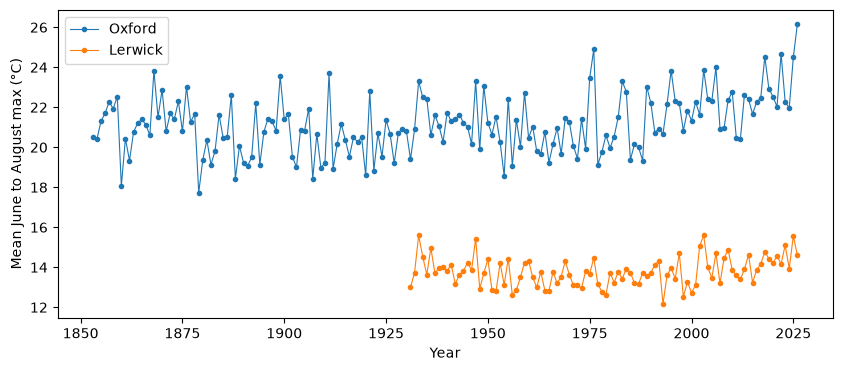

In [22]:
summers = both[both["mm"].isin([6, 7, 8])].groupby(["station", "yyyy"])["tmax"].mean()
fig, ax = plt.subplots(figsize=(10, 4))
for station in ["Oxford", "Lerwick"]:
    ax.plot(summers[station].index, summers[station], marker=".", linewidth=0.8, label=station)
ax.set_xlabel("Year")
ax.set_ylabel("Mean June to August max (°C)")
ax.legend()
plt.show()

In [23]:
summers["Lerwick"].sort_values(ascending=False).head(3)

yyyy
1933    15.600000
2003    15.600000
2025    15.566667
Name: tmax, dtype: float64

**Answer.** No. 2026 is not even in Lerwick's top three summers. The heat of 2026 was a southern story, which is exactly why one station is not enough to talk about "the UK".

The same numbers in **wide** form, one column per station, can be easier to read side by side:

In [24]:
summers.unstack("station").tail(3)

station,Lerwick,Oxford
yyyy,,
2024,13.933333,21.966667
2025,15.566667,24.500000
2026,14.600000,26.166667


## 5. Machine learning with scikit-learn

*12:10, 40 minutes*

scikit-learn gives every model the same three methods: `fit` (learn from data), `predict` (make predictions) and `score` (measure how good they are). Learn the pattern once and every model works the same way. The [CfRR Scikit-Learn page](https://coding-for-reproducible-research.github.io/CfRR_Courses/individual_modules/python_for_data_analysis/Python_ScikitLearn.html) covers more models.

### The same line, two ways

A straight-line trend is the simplest model there is. scikit-learn expects the inputs as a two-dimensional table (one row per example, one column per input), hence the `reshape`.

In [25]:
from sklearn.linear_model import LinearRegression

X = before.index.to_numpy().reshape(-1, 1)
y = before.to_numpy()
model = LinearRegression().fit(X, y)
model.coef_[0], trend_slope

(np.float64(0.04121439963545227), np.float64(0.04121439963545141))

The same slope as `np.polyfit`. scikit-learn is the same idea with more ceremony, and the ceremony pays off once models get more complicated.

### Testing a model honestly

A model should be judged on data it has not seen. The usual approach is to hold back some data as a **test set**.

In [26]:
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

X_all = summer_tmax.index.to_numpy().reshape(-1, 1)
y_all = summer_tmax.to_numpy()
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.25, random_state=42)
model = LinearRegression().fit(X_train, y_train)
mean_absolute_error(y_test, model.predict(X_test))  # average error in °C

1.1017859214150052

**Spot the bug.** This code runs, and the error looks respectable. But `train_test_split` picks the test summers at random. Why is that a problem for data that run through time?

**Answer.** Each test summer is surrounded by training summers on both sides, so the model only has to fill in gaps, not predict the future. The score flatters it. With time series, train on the past and test on the future.

**Modify.** Split by year instead: train on summers before 2000, test on 2000 onwards. How does the error compare?

In [27]:
train = X_all[:, 0] < 2000
model = LinearRegression().fit(X_all[train], y_all[train])
mean_absolute_error(y_all[~train], model.predict(X_all[~train]))

1.5636258940890375

### Oxford or Lerwick?

Our main model is a **classifier**: given one month's weather, which station is it? The answer is a category rather than a number. We use months from 1931 onwards, when both stations recorded everything, and split by year again.

In [28]:
FEATURES = ["tmax", "tmin", "rain", "sun"]
data = both[both["yyyy"] >= 1931].dropna(subset=FEATURES)
train = data[data["yyyy"] < 2000]
test = data[data["yyyy"] >= 2000]
test["station"].value_counts()

station
Oxford     321
Lerwick    321
Name: count, dtype: int64

**Predict.** Before fitting anything: what accuracy would you get by guessing at random? And with a one-line rule such as "if `tmax` is below 12 °C, it's Lerwick"?

In [29]:
guess = np.where(test["tmax"] < 12, "Lerwick", "Oxford")
(guess == test["station"]).mean()

np.float64(0.6588785046728972)

These are **baselines**. A model is only worth having if it beats them. Now the model: a decision tree, which learns a series of yes/no questions about the inputs.

In [30]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(train[FEATURES], train["station"])
tree.score(test[FEATURES], test["station"])

0.8084112149532711

**Investigate.** Is that good? Compare it with the two baselines. Which months might it get wrong? (Think about a warm Lerwick summer and a cold Oxford winter.)

**Answer.** Clearly better than guessing (50%) and better than the one-line rule, but far from perfect. Temperature alone mixes up the seasons: a Lerwick July and an Oxford April can look alike.

**Make (stretch).** Think about how a coastal climate differs from an inland one. Invent one new column from the existing ones, add it to the features and refit. Does it help?

In [31]:
# Coastal climates have a small gap between day and night temperatures
data = data.assign(trange=data["tmax"] - data["tmin"])
train = data[data["yyyy"] < 2000]
test = data[data["yyyy"] >= 2000]
features = FEATURES + ["trange"]
tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(train[features], train["station"])
tree.score(test[features], test["station"])

0.9735202492211839

**Answer.** A big jump. The sea keeps Lerwick's nights mild and its days cool, so its daily temperature range is small. One well-chosen input, based on knowing the subject, beats a more complicated model.

## 6. Wrap: so, was summer 2026 unusual?

*12:50, 10 minutes*

In [32]:
previous = summer_tmax.drop(2026)
print(f"Summer 2026 mean max: {summer_tmax[2026]:.1f} °C")
print(f"Previous record: {previous.max():.1f} °C in {previous.idxmax()}")
print(f"Above the 1970 to 2025 trend by {summer_tmax[2026] - expected_2026:.1f} °C")
print(f"Typical scatter around the trend: {scatter:.1f} °C")

Summer 2026 mean max: 26.2 °C
Previous record: 24.9 °C in 1976
Above the 1970 to 2025 trend by 3.2 °C
Typical scatter around the trend: 1.3 °C


**Decide together.** Given all of this, what would you write in one sentence? What caveats belong in it?

**Suggested.** Summer 2026 was the hottest in Oxford's record, which goes back to 1853, by more than a degree, and well above what even the recent warming trend would predict; the figures are still provisional, and the analysis should be rerun on a later snapshot once the Met Office confirms them.

### Reproducibility checklist

- **Pinned data:** a dated snapshot at a fixed address, with its source and checksum in the course repository's [data README](https://github.com/cafoala/cfrr-python-for-data-analysis/blob/main/data/README.md).
- **Locked libraries:** `uv.lock` records exact versions; `requirements.txt` is exported from it for pip users.
- **Fresh kernel:** the notebook runs top to bottom after a restart.
- **Seeds:** every random step has a `random_state`.
- **Flags kept:** estimated, provisional and automatic-sensor values are marked, not dropped.
- **Checks:** `assert` statements catch silent mistakes when the code meets new data.

### Demo: uv (optional)

uv is a fast replacement for `pip` and `venv`. In a copy of the course repository:

```bash
uv sync             # create .venv with exactly the versions in uv.lock
uv run jupyter lab  # start JupyterLab inside that environment
uv add seaborn      # add a library and update the lock file
```

If you prefer pip, `pip install -r requirements.txt` gives you the same versions.

### Where next

- [Introduction to Machine Learning](https://coding-for-reproducible-research.github.io/CfRR_Courses/programme_information/introduction_to_machine_learning.html)
- [Software Development Best Practices](https://coding-for-reproducible-research.github.io/CfRR_Courses/programme_information/software_development_best_practices.html), for proper testing
- [Version Control](https://coding-for-reproducible-research.github.io/CfRR_Courses/programme_information/version_control.html)